# Ch 8.3.3 - 8.3.4 R Lab

In [1]:
# Setup from 8.3.2: the pasted code relies on train and boston.test
library(MASS)
set.seed(1)
train <- sample(1:nrow(Boston), nrow(Boston) / 2)
boston.test <- Boston[-train, "medv"]

In [2]:
# 8.3.3 Bagging: mtry = 13 uses all predictors at each split
library(randomForest)
set.seed(1)
bag.boston <- randomForest(medv ~ ., data = Boston, subset = train,
                           mtry = 13, importance = TRUE)
bag.boston

randomForest 4.7-1.2



Type rfNews() to see new features/changes/bug fixes.




Call:
 randomForest(formula = medv ~ ., data = Boston, mtry = 13, importance = TRUE,      subset = train) 
               Type of random forest: regression
                     Number of trees: 500
No. of variables tried at each split: 13

          Mean of squared residuals: 11.13274
                    % Var explained: 85.52

[1] 23.59536

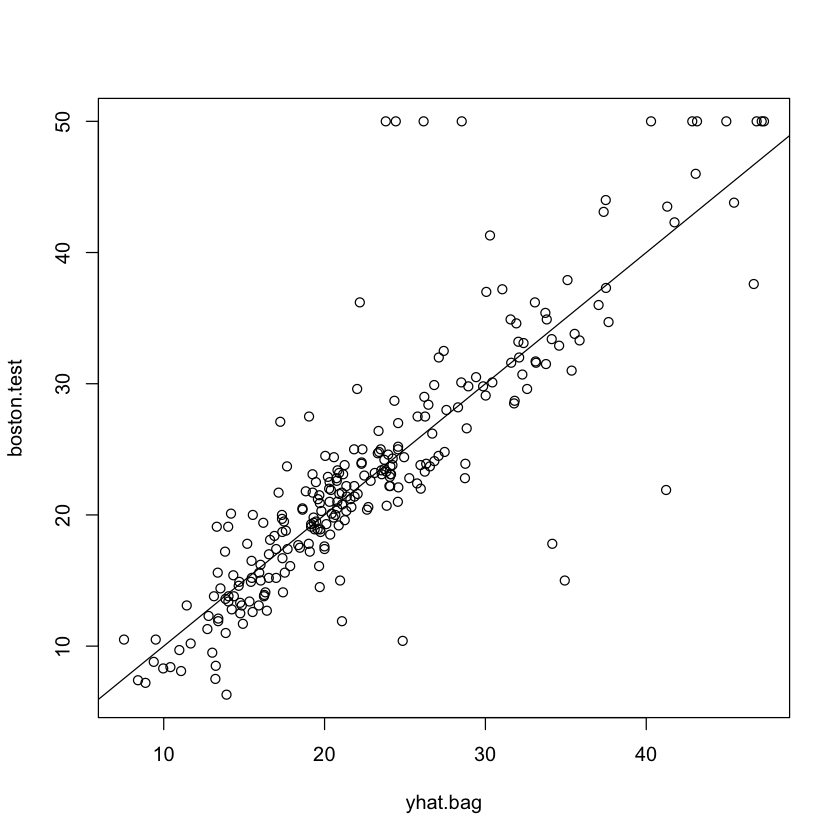

In [3]:
yhat.bag <- predict(bag.boston, newdata = Boston[-train, ])
plot(yhat.bag, boston.test)
abline(0, 1)
mean((yhat.bag - boston.test)^2)

In [4]:
# Bagging with only 25 trees
bag.boston <- randomForest(medv ~ ., data = Boston, subset = train,
                           mtry = 13, ntree = 25)
yhat.bag <- predict(bag.boston, newdata = Boston[-train, ])
mean((yhat.bag - boston.test)^2)

[1] 24.2555

In [5]:
# Random forest: mtry = 6
set.seed(1)
rf.boston <- randomForest(medv ~ ., data = Boston, subset = train,
                          mtry = 6, importance = TRUE)
yhat.rf <- predict(rf.boston, newdata = Boston[-train, ])
mean((yhat.rf - boston.test)^2)

[1] 19.77335

In [6]:
importance(rf.boston)

,%IncMSE,IncNodePurity
crim,16.5378819,1092.03042
zn,2.3197099,114.08552
indus,5.4311214,557.11097
chas,0.6947007,32.84033
nox,10.7526431,759.95101
rm,32.2338888,7890.18004
age,13.8971778,563.65986
dis,9.7323920,757.79153
rad,1.7401422,105.22582
tax,7.8417322,310.41915


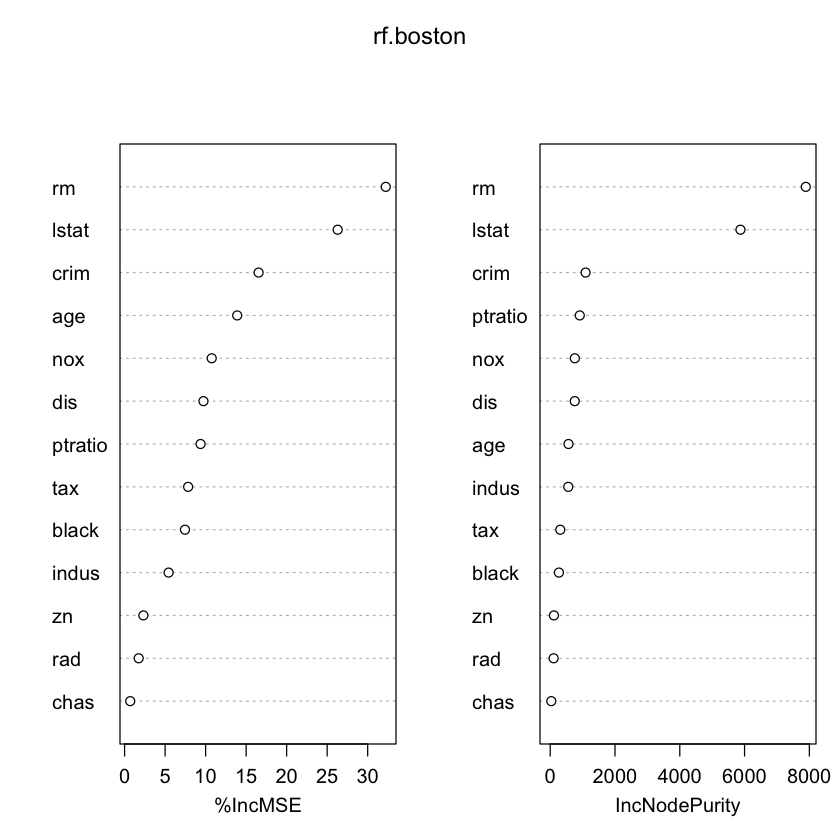

In [7]:
varImpPlot(rf.boston)

In [8]:
# 8.3.4 Boosting
library(gbm)
set.seed(1)
boost.boston <- gbm(medv ~ ., data = Boston[train, ], distribution = "gaussian",
                    n.trees = 5000, interaction.depth = 4)

Loaded gbm 2.3.1



This version of gbm is no longer under development. Consider transitioning to gbm3, https://github.com/gbm-developers/gbm3



,var,rel.inf
,<chr>,<dbl>
rm,rm,43.9919329
lstat,lstat,33.1216941
crim,crim,4.2604167
dis,dis,4.0111090
nox,nox,3.4353017
black,black,2.8267554
age,age,2.6113938
ptratio,ptratio,2.5403035
tax,tax,1.4565654


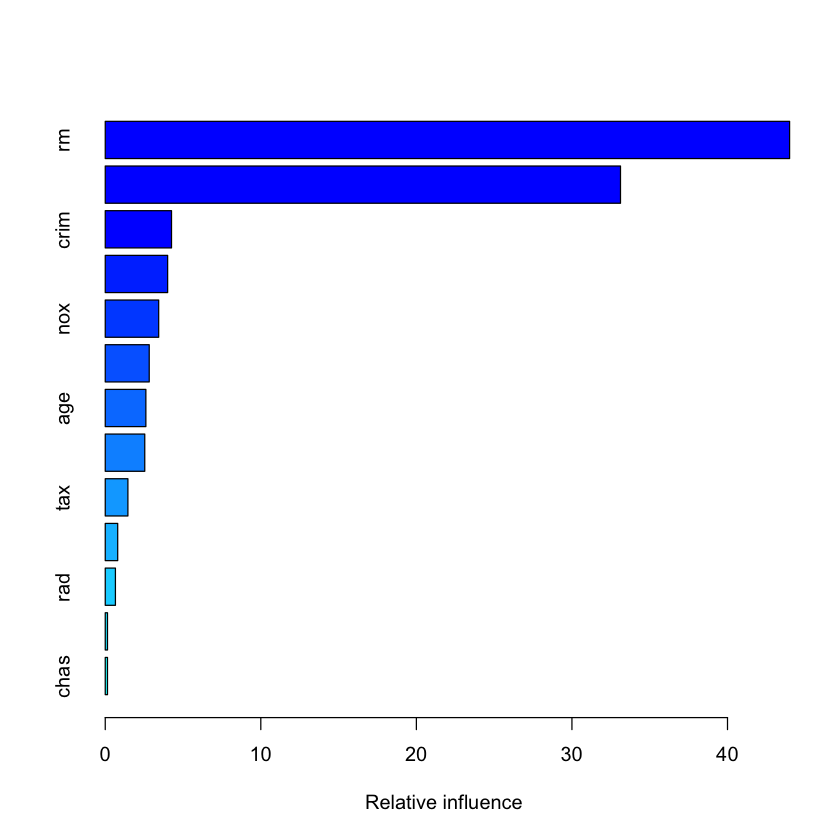

In [9]:
summary(boost.boston)

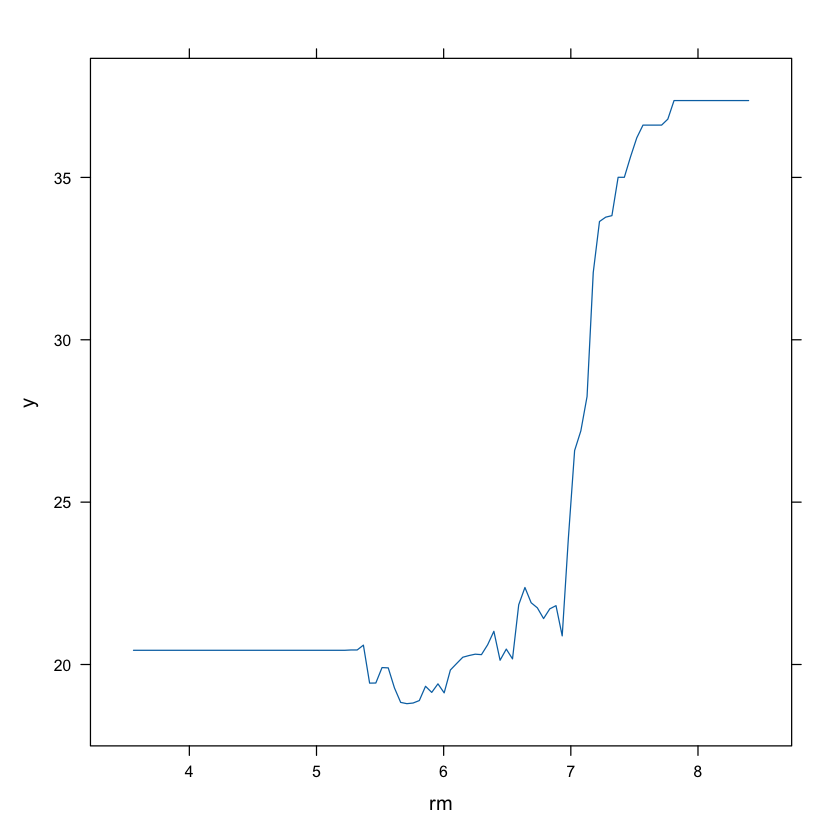

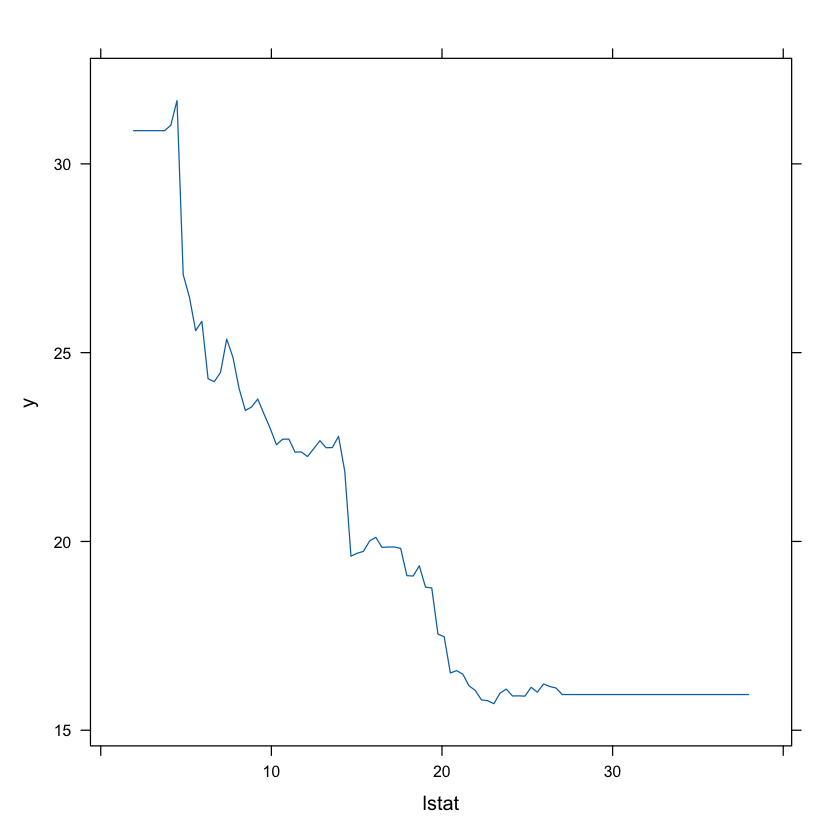

In [10]:
# Partial dependence plots
par(mfrow = c(1, 2))
plot(boost.boston, i = "rm")
plot(boost.boston, i = "lstat")

In [11]:
yhat.boost <- predict(boost.boston, newdata = Boston[-train, ], n.trees = 5000)
mean((yhat.boost - boston.test)^2)

[1] 18.84709

In [12]:
# Boosting with shrinkage (lambda) = 0.2
boost.boston <- gbm(medv ~ ., data = Boston[train, ], distribution = "gaussian",
                    n.trees = 5000, interaction.depth = 4, shrinkage = 0.2,
                    verbose = FALSE)
yhat.boost <- predict(boost.boston, newdata = Boston[-train, ], n.trees = 5000)
mean((yhat.boost - boston.test)^2)

[1] 18.33455